# Electrode and fish factors over the day (71 recordings, my model in the camera tank)

**Ratios** (`EOD_gain_fish_x_signed_electrode_71_mine_tank_4fish_kaden.ipynb`): the 1000 best clean isolated EODs per fish
(selected with Denis' pipeline, run of 2026-11-05/06 with my mask midline), $g = |V_\text{rec}| / |V_\text{pred}|$ on the 2 loudest
pairs with my model's prediction for the emitter, each ratio under the signed electrode nearer to the emitter.

**Time**: clock time of the EOD = the recording's start time (in its name, 2024-02-20T<hh_mm_ss>) + frame / 50 s.

**Electrode factor over time**: each ratio divided by its fish's median factor, $g / a_f$, against time, one panel per signed
electrode (dot colour: fish). Black: median per 2-hour bin with 25–75%. Dashed: the electrode's median over the whole day.
ρ: Spearman correlation of $g/a_f$ with time.

**Fish factor over time**: each ratio divided by its electrode's median factor, $g / e_k$, against time, one panel per fish.

**Fish factor vs measured length**: per fish and recording, the median of $g / e_k$ against the fish's length measured in that
recording (90th percentile of its mask midline arc length over the recording's EOD frames, 15.2 px/cm), only fish-recordings with
≥ 10 ratios.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import spearmanr
%matplotlib inline

BASE, LET, P = 'results/eod_assign_4fish_kaden', 'ABCD', 912
SRC = f'{BASE}/clean_emitter_set_71/gain_mine_tank_int4'
OUT = f'{SRC}/vs_time'; os.makedirs(OUT, exist_ok=True)
FISH_COL = {'A': '#1F5FBF', 'B': '#17A0B0', 'C': '#F08A24', 'D': '#C8361E'}
ORDER = [f'{p}{s}' for p in range(1, 11) for s in ('+', '−')]
PX_CM_DENIS = 912 / 60
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': '#e6e6e3',
                     'axes.axisbelow': True, 'axes.edgecolor': '#8a8a85', 'axes.labelcolor': '#2b2b2b',
                     'xtick.color': '#5a5a55', 'ytick.color': '#5a5a55'})
D = pd.read_csv(f'{SRC}/ratios_best1000.csv'); D = D[D.kept].reset_index(drop=True)
F = pd.read_csv(f'{SRC}/voltage_rule_factors_median.csv').set_index('factor').value
A_MED = D.fish.map({f: F[f'fish {f}'] for f in LET}); E_MED = D.electrode.map({e: F[f'electrode {e}'] for e in ORDER})
D['g_over_a'] = D.gain / A_MED; D['g_over_e'] = D.gain / E_MED
hms = D.video.str.split('_', expand=True).astype(int)
D['hour'] = hms[0] + hms[1] / 60 + hms[2] / 3600 + D.Frame / 50 / 3600
BINS = np.arange(0, 26, 2)
print(f'{len(D)} ratios from {D.video.nunique()} recordings, {D.hour.min():.2f} h to {D.hour.max():.2f} h')

def binned(ax, x, y):
    b = np.digitize(x, BINS) - 1; c = (BINS[:-1] + BINS[1:]) / 2; med, q1, q3 = [], [], []
    for i in range(len(c)):
        v = y[b == i]
        med.append(np.median(v) if len(v) >= 5 else np.nan); q1.append(np.percentile(v, 25) if len(v) >= 5 else np.nan); q3.append(np.percentile(v, 75) if len(v) >= 5 else np.nan)
    med, q1, q3 = map(np.array, (med, q1, q3))
    ax.fill_between(c, q1, q3, color='#2b2b2b', alpha=0.12, lw=0); ax.plot(c, med, '-o', color='#2b2b2b', ms=3.5, lw=1.5)

7997 ratios from 70 recordings, 0.22 h to 24.27 h


## Electrode factors over the day

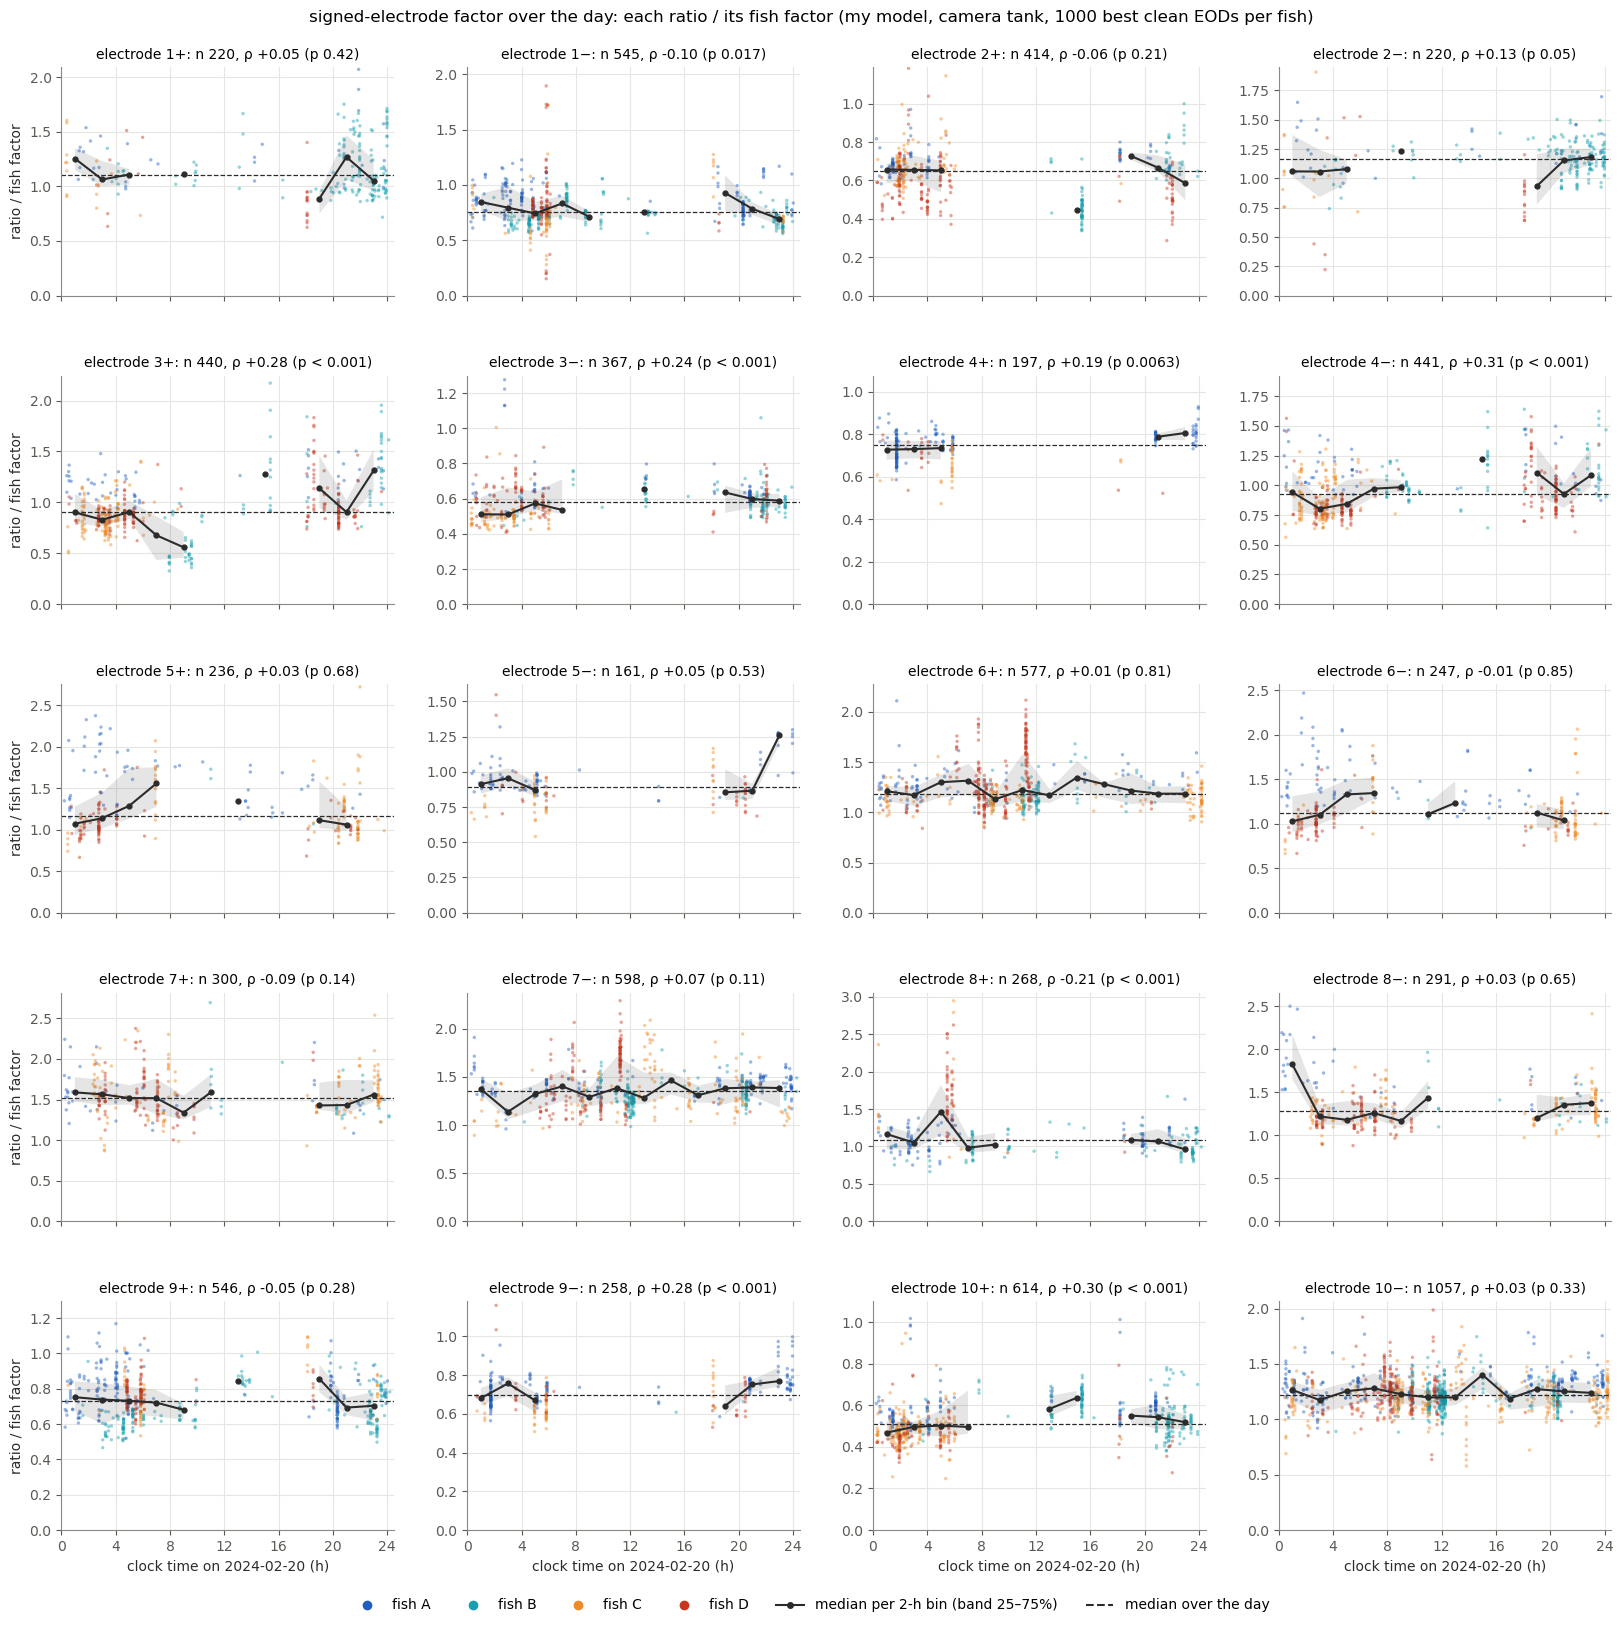

,electrode,n,median,rho_time,p,hours
0,1+,220,1.102,0.055,0.419,0.3-24.0
1,1−,545,0.753,-0.102,0.017,0.3-24.0
2,2+,414,0.647,-0.061,0.212,0.3-23.9
3,2−,220,1.161,0.132,0.050,0.3-24.0
4,3+,440,0.901,0.280,0.000,0.4-24.1
5,3−,367,0.578,0.237,0.000,0.3-23.9
6,4+,197,0.746,0.194,0.006,0.3-24.0
7,4−,441,0.923,0.312,0.000,0.4-24.1
8,5+,236,1.169,0.027,0.676,0.2-23.8
9,5−,161,0.894,0.050,0.527,0.3-24.0


In [2]:
fig, axs = plt.subplots(5, 4, figsize=(20, 19), sharex=True, gridspec_kw=dict(hspace=0.35, wspace=0.22))
rows = []
for ax, e in zip(axs.ravel(), ORDER):
    d = D[D.electrode == e]
    if len(d) == 0: ax.set_title(f'{e}: no ratios', fontsize=10); continue
    for f in LET:
        k = d.fish == f
        ax.scatter(d.hour[k], d.g_over_a[k], s=6, alpha=0.45, color=FISH_COL[f], edgecolor='none')
    binned(ax, d.hour.to_numpy(), d.g_over_a.to_numpy())
    ax.axhline(F[f'electrode {e}'], color='#2b2b2b', ls='--', lw=0.9)
    rho, pv = spearmanr(d.hour, d.g_over_a) if len(d) > 5 else (np.nan, np.nan)
    rows.append(dict(electrode=e, n=len(d), median=F[f'electrode {e}'], rho_time=rho, p=pv, hours=f'{d.hour.min():.1f}-{d.hour.max():.1f}'))
    ax.set(ylim=(0, np.percentile(d.g_over_a, 99) * 1.2), xlim=(0, 24.5), xticks=range(0, 25, 4))
    ax.set_title(f'electrode {e}: n {len(d)}, ρ {rho:+.2f}' + (' (p < 0.001)' if pv < 0.001 else f' (p {pv:.2g})'), fontsize=10)
for ax in axs[-1]: ax.set_xlabel('clock time on 2024-02-20 (h)')
for ax in axs[:, 0]: ax.set_ylabel('ratio / fish factor')
h = [Line2D([], [], marker='o', ls='', color=FISH_COL[f], label=f'fish {f}') for f in LET] + \
    [Line2D([], [], color='#2b2b2b', marker='o', ms=4, label='median per 2-h bin (band 25–75%)'), Line2D([], [], color='#2b2b2b', ls='--', label='median over the day')]
fig.legend(handles=h, loc='lower center', ncol=6, frameon=False, fontsize=10, bbox_to_anchor=(0.5, 0.06))
fig.suptitle('signed-electrode factor over the day: each ratio / its fish factor (my model, camera tank, 1000 best clean EODs per fish)', fontsize=12, y=0.91)
fig.savefig(f'{OUT}/electrode_factor_vs_time.png', dpi=95, bbox_inches='tight'); plt.show()
ET = pd.DataFrame(rows); ET.to_csv(f'{OUT}/electrode_factor_vs_time.csv', index=False); display(ET.round(3))

## Fish factors over the day

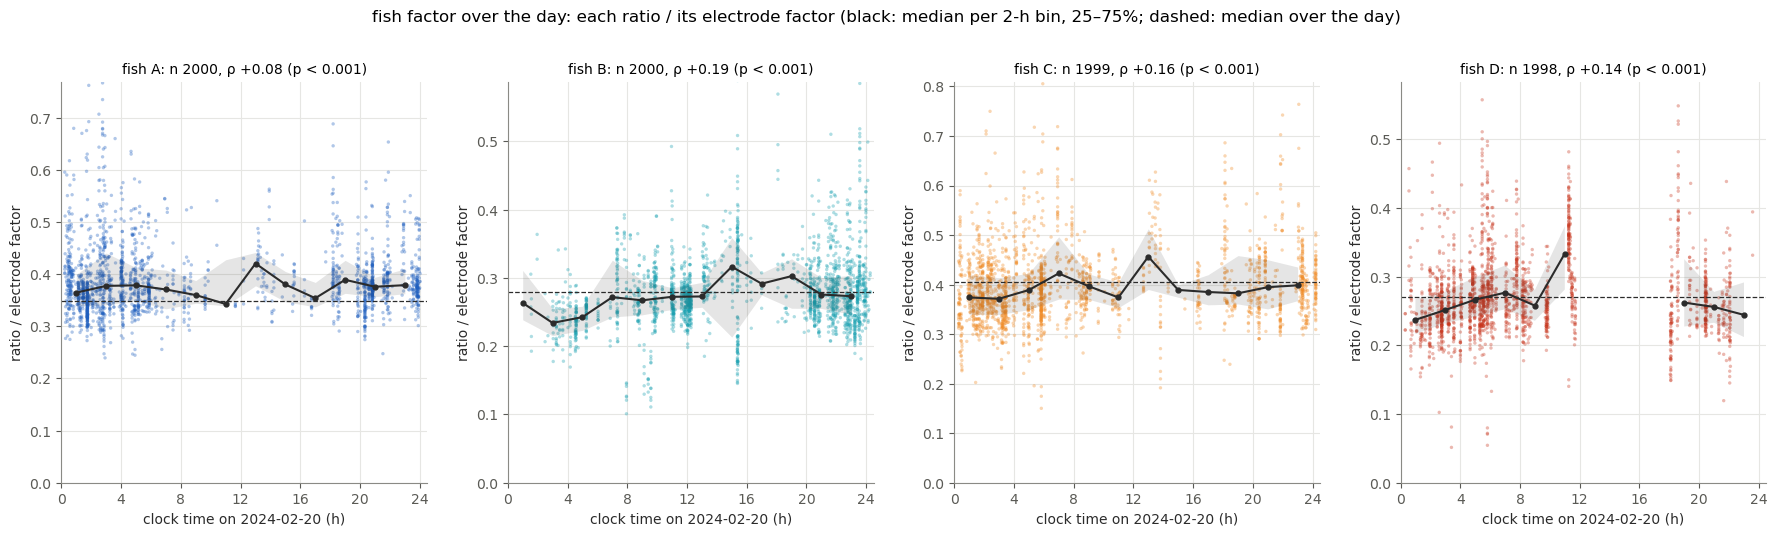

,fish,n,median,rho_time,p,n_recordings,recording_median_min,recording_median_max
0,A,2000,0.348,0.080,0.0,53,0.338,0.498
1,B,2000,0.279,0.186,0.0,57,0.220,0.579
2,C,1999,0.405,0.162,0.0,56,0.334,0.536
3,D,1998,0.270,0.143,0.0,39,0.225,0.363


In [3]:
fig, axs = plt.subplots(1, 4, figsize=(22, 5.2), gridspec_kw=dict(wspace=0.22))
rows = []
for ax, f in zip(axs, LET):
    d = D[D.fish == f]
    ax.scatter(d.hour, d.g_over_e, s=6, alpha=0.35, color=FISH_COL[f], edgecolor='none')
    binned(ax, d.hour.to_numpy(), d.g_over_e.to_numpy())
    ax.axhline(F[f'fish {f}'], color='#2b2b2b', ls='--', lw=0.9)
    rho, pv = spearmanr(d.hour, d.g_over_e)
    per_rec = d.groupby('video').g_over_e.median()
    rows.append(dict(fish=f, n=len(d), median=F[f'fish {f}'], rho_time=rho, p=pv, n_recordings=d.video.nunique(),
                     recording_median_min=per_rec.min(), recording_median_max=per_rec.max()))
    ax.set(ylim=(0, np.percentile(d.g_over_e, 99) * 1.2), xlim=(0, 24.5), xticks=range(0, 25, 4), xlabel='clock time on 2024-02-20 (h)', ylabel='ratio / electrode factor')
    ax.set_title(f'fish {f}: n {len(d)}, ρ {rho:+.2f}' + (' (p < 0.001)' if pv < 0.001 else f' (p {pv:.2g})'), fontsize=10)
fig.suptitle('fish factor over the day: each ratio / its electrode factor (black: median per 2-h bin, 25–75%; dashed: median over the day)', fontsize=12, y=1.02)
fig.savefig(f'{OUT}/fish_factor_vs_time.png', dpi=100, bbox_inches='tight'); plt.show()
FT = pd.DataFrame(rows); FT.to_csv(f'{OUT}/fish_factor_vs_time.csv', index=False); display(FT.round(3))

## Fish factor vs fish length measured in each recording

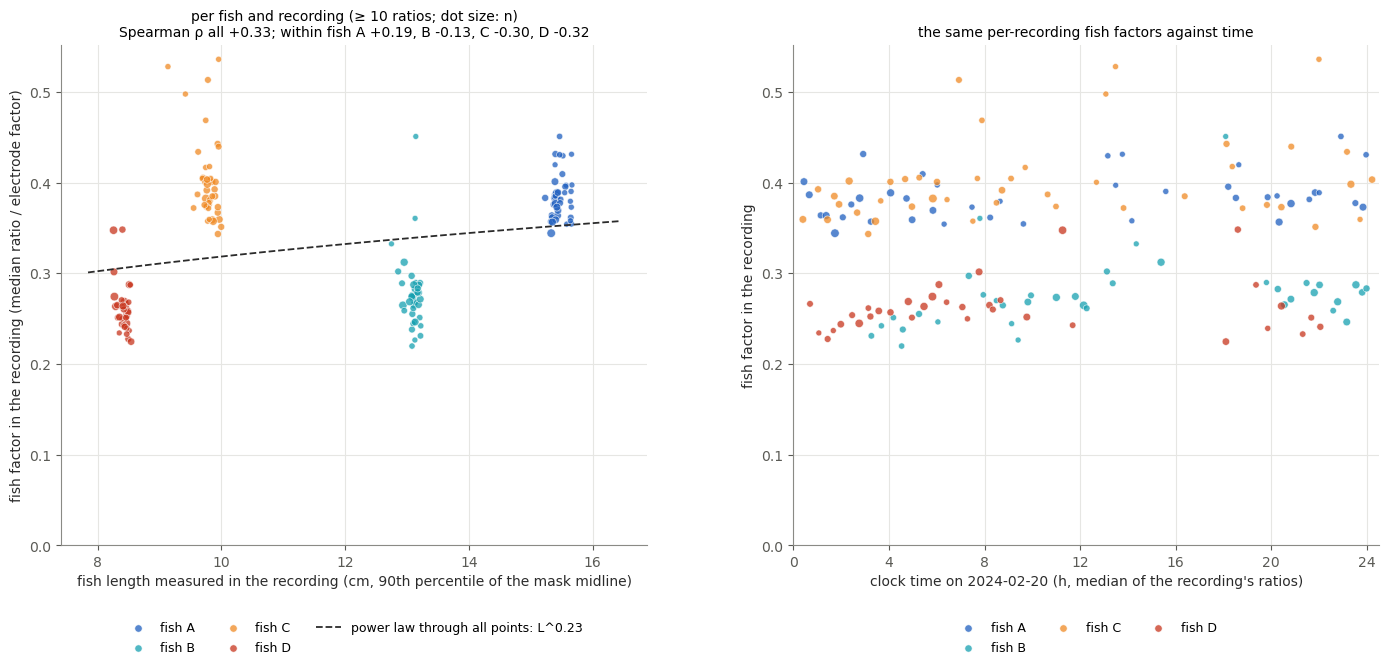

,recordings,L90_min,L90_max,factor_min,factor_median,factor_max
fish,,,,,,
A,40,15.234,15.666,0.344,0.383,0.451
B,38,12.748,13.222,0.220,0.273,0.451
C,44,9.135,9.996,0.343,0.389,0.536
D,34,8.255,8.539,0.225,0.258,0.348


In [4]:
lens = []
for t in sorted(D.video.unique()):
    z = np.load(f'{BASE}/{t}/midlines_by_frame.npz'); M = z['mids'] * (P - 1)                    # (n, 4, 101, 2) px
    L = np.linalg.norm(np.diff(M, axis=2), axis=-1).sum(-1) / PX_CM_DENIS                        # (n, 4) cm
    for j, f in enumerate(LET):
        v = L[:, j][np.isfinite(L[:, j])]
        lens.append(dict(video=t, fish=f, L90_cm=np.percentile(v, 90) if len(v) else np.nan))
LV = pd.DataFrame(lens)
G = D.groupby(['video', 'fish']).agg(factor=('g_over_e', 'median'), n=('g_over_e', 'size'), hour=('hour', 'median')).reset_index().merge(LV, on=['video', 'fish'])
G = G[G.n >= 10]; G.to_csv(f'{OUT}/fish_factor_per_recording_vs_length.csv', index=False)
fig, axs = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw=dict(wspace=0.25))
for f in LET:
    g = G[G.fish == f]
    axs[0].scatter(g.L90_cm, g.factor, s=12 + 2 * np.sqrt(g.n), color=FISH_COL[f], alpha=0.75, edgecolor='white', lw=0.5, label=f'fish {f}')
    axs[1].scatter(g.hour, g.factor, s=12 + 2 * np.sqrt(g.n), color=FISH_COL[f], alpha=0.75, edgecolor='white', lw=0.5, label=f'fish {f}')
x, y = G.L90_cm.to_numpy(), G.factor.to_numpy(); e_, lk = np.polyfit(np.log(x), np.log(y), 1); xs = np.linspace(x.min() * 0.95, x.max() * 1.05, 50)
rho_all = spearmanr(x, y)[0]; rho_within = {f: spearmanr(G[G.fish == f].L90_cm, G[G.fish == f].factor)[0] for f in LET if (G.fish == f).sum() > 3}
axs[0].plot(xs, np.exp(lk) * xs ** e_, color='#2b2b2b', ls='--', lw=1.3, label=f'power law through all points: L^{e_:.2f}')
axs[0].set(xlabel='fish length measured in the recording (cm, 90th percentile of the mask midline)', ylabel='fish factor in the recording (median ratio / electrode factor)', ylim=(0, None))
axs[0].set_title(f'per fish and recording (≥ 10 ratios; dot size: n)\nSpearman ρ all {rho_all:+.2f}; within fish ' +
                 ', '.join(f'{f} {r:+.2f}' for f, r in rho_within.items()), fontsize=10)
axs[1].set(xlabel='clock time on 2024-02-20 (h, median of the recording\'s ratios)', ylabel='fish factor in the recording', ylim=(0, None), xlim=(0, 24.5), xticks=range(0, 25, 4))
axs[1].set_title('the same per-recording fish factors against time', fontsize=10)
for ax in axs: ax.legend(frameon=False, fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=3)
fig.savefig(f'{OUT}/fish_factor_per_recording_vs_length_and_time.png', dpi=100, bbox_inches='tight'); plt.show()
display(G.groupby('fish').agg(recordings=('video', 'size'), L90_min=('L90_cm', 'min'), L90_max=('L90_cm', 'max'),
                              factor_min=('factor', 'min'), factor_median=('factor', 'median'), factor_max=('factor', 'max')).round(3))